# **Bahrain GP 2025: Exploratory Data Analysis**

**Project:** F1 Race Strategy Simulator · **Phase 0:** First contact with real race data

### Objective
Load one real race, understand the structure of the lap and tyre data, and plot lap times by tyre compound. This is the starting point for the tyre degradation model.

### Data source
[OpenF1 API](https://openf1.org): free, no authentication. Used instead of FastF1 because the official F1 live-timing archive started requiring authentication in October 2026.

### Contents
1. Setup
2. Data access (OpenF1 with local cache)
3. Race laps
4. Tyre data (stints) and the laps-stints join
5. Lap times by compound: hypotheses vs data
6. Summary and next steps

### How to run
Run all cells from top to bottom using the project's `.venv` kernel. The first run downloads data from OpenF1; later runs read it from `data/cache/openf1/`.

## 1. Setup

### 1.1 Environment and imports
All imports live in this cell, so dependencies are visible at a glance. Printing versions makes results easier to reproduce later.

In [1]:
# All imports
import sys
import json
from pathlib import Path

import requests
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# Confirm this notebook runs on the project's virtual environment
print(f"Python:     {sys.version.split()[0]}")
print(f"In venv:    {'.venv' in sys.executable}")   # True = running on the project's venv
print(f"pandas:     {pd.__version__}")
print(f"requests:   {requests.__version__}")
print(f"matplotlib: {matplotlib.__version__}")

Python:     3.14.6
In venv:    True
pandas:     2.3.3
requests:   2.34.2
matplotlib: 3.11.2


### 1.2 Project paths and cache
Jupyter runs with the notebook's folder (`notebooks/`) as working directory, so relative paths like `data/cache` would point to the wrong place. `find_project_root()` walks up the folder tree until it finds `requirements.txt`, which only exists at the project root.

In [2]:
def find_project_root(marker: str = "requirements.txt") -> Path:
    """Walk up from the current working directory until a folder containing `marker` is found.

    Using a marker file (instead of assuming a fixed depth like Path.cwd().parent)
    keeps this working even if the notebook is moved to another subfolder.
    """
    current = Path.cwd().resolve()
    for folder in [current, *current.parents]:
        if (folder / marker).exists():
            return folder
    raise FileNotFoundError(f"Could not find '{marker}' in {current} or any parent folder.")


PROJECT_ROOT = find_project_root()

# One subfolder per data source keeps caches from different APIs separated
CACHE_DIR = PROJECT_ROOT / "data" / "cache" / "openf1"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT.name}")                    # Only the folder name
print(f"Cache dir:    {CACHE_DIR.relative_to(PROJECT_ROOT)}")  # Path relative to the root

Project root: f1-strategy-simulator
Cache dir:    data\cache\openf1


## 2. Data access: OpenF1 with a local cache

`fetch_openf1()` wraps every API request:
- **Cache:** each response is saved as a JSON file in `data/cache/openf1/`. Repeated
  requests are read from disk: faster, gentler on the free API, and the data survives
  even if the source changes (as happened with the F1 archive in October 2026).
- **Fail fast:** HTTP errors raise an exception, and empty responses are never cached.

In [3]:
OPENF1_BASE_URL = "https://api.openf1.org/v1"


def fetch_openf1(endpoint: str, params: dict) -> list[dict]:
    """Fetch records from an OpenF1 endpoint, using a local JSON file as cache.

    First call: downloads from the API and saves the response to disk.
    Next calls with the same endpoint + params: reads the file, no network needed.
    """
    # Build a deterministic file name from the request. Sorting the params ensures
    # {"a": 1, "b": 2} and {"b": 2, "a": 1} map to the same cache file.
    param_str = "_".join(f"{key}={value}" for key, value in sorted(params.items()))
    cache_file = CACHE_DIR / f"{endpoint}__{param_str}.json"

    if cache_file.exists():
        print(f"[cache] {cache_file.name}")
        return json.loads(cache_file.read_text(encoding="utf-8"))

    print(f"[api]   GET /{endpoint} {params}")
    # requests builds the "?key=value&..." part of the URL from the params dict
    response = requests.get(f"{OPENF1_BASE_URL}/{endpoint}", params=params, timeout=30)

    # Fail fast: turn HTTP errors (401, 404, 429, 500...) into a visible exception,
    # instead of silently continuing like FastF1's load() did
    response.raise_for_status()
    data = response.json()

    # Never cache an empty answer: it would hide the problem on every future run
    if not data:
        raise ValueError(f"OpenF1 returned no data for /{endpoint} with {params}")

    cache_file.write_text(json.dumps(data), encoding="utf-8")
    return data

## 3. Race laps

### 3.1 Find the session
OpenF1 identifies each session with a numeric `session_key`, used by every later request.
The `assert` guarantees the filters match exactly one race.

In [4]:
# Find the session: OpenF1 identifies every session with a numeric session_key
sessions = fetch_openf1(
    "sessions",
    {"year": 2025, "country_name": "Bahrain", "session_name": "Race"},
)

# Fail fast: we expect exactly one race to match these filters
assert len(sessions) == 1, f"Expected 1 session, got {len(sessions)}"

race = sessions[0]
SESSION_KEY = race["session_key"]   # Constant used by every later request

print(f"Session key: {SESSION_KEY}")
print(f"Circuit:     {race['circuit_short_name']}")
print(f"Start:       {race['date_start']}")

[cache] sessions__country_name=Bahrain_session_name=Race_year=2025.json
Session key: 10014
Circuit:     Sakhir
Start:       2025-04-13T15:00:00+00:00


### 3.2 Load all laps
One row = one lap of one driver. Notes on the raw data:
- `lap_duration` is already in seconds (float).
- `date_start` is a text timestamp (to be converted with `pd.to_datetime` later).
- `segments_sector_*` hold mini-sector lists, not needed for degradation.
- There is a pit-out flag (`is_pit_out_lap`) but no pit-in flag (that is in the `/pit` endpoint).

In [5]:
# All laps of all drivers in the race (one API call, cached afterwards)
laps_raw = fetch_openf1("laps", {"session_key": SESSION_KEY})

# A list of dicts converts directly to a DataFrame: each dict becomes a row,
# each key becomes a column
laps = pd.DataFrame(laps_raw)

print(laps.shape)             # (rows, columns): one row = one lap of one driver
print(laps.columns.tolist())  # Column names, to see what OpenF1 gives us
laps.head()                   # Last line of a cell is displayed as a table

[cache] laps__session_key=10014.json
(1129, 16)
['meeting_key', 'session_key', 'driver_number', 'lap_number', 'date_start', 'duration_sector_1', 'duration_sector_2', 'duration_sector_3', 'i1_speed', 'i2_speed', 'is_pit_out_lap', 'lap_duration', 'segments_sector_1', 'segments_sector_2', 'segments_sector_3', 'st_speed']


,meeting_key,session_key,driver_number,lap_number,date_start,duration_sector_1,duration_sector_2,duration_sector_3,i1_speed,i2_speed,is_pit_out_lap,lap_duration,segments_sector_1,segments_sector_2,segments_sector_3,st_speed
0,1257,10014,81,1,2025-04-13T15:03:49.173000+00:00,33.127,42.130,23.956,233.0,244.0,False,99.213,"[None, 0, 2049, 2049, 2051, 2051, 2049, 2049, ...","[2051, 2051, 2051, 2049, 2051, 2049, 2049, 204...","[2049, 2049, 2049, 2049, 2049, 2049, 2051]",250.0
1,1257,10014,16,1,2025-04-13T15:03:49.173000+00:00,34.565,43.164,24.036,233.0,250.0,False,101.765,"[None, 0, 2049, 2049, 2049, 2049, 2049, 2049, ...","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2049, 2049, 2049, 2049, 2049, 2051]",256.0
2,1257,10014,63,1,2025-04-13T15:03:49.173000+00:00,33.821,42.305,23.820,232.0,249.0,False,99.946,"[None, 0, 2049, 2051, 2049, 2049, 2049, 2049, ...","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 205...","[2051, 2049, 2049, 2051, 2049, 2051, 2051]",251.0
3,1257,10014,55,1,2025-04-13T15:03:49.173000+00:00,35.564,43.370,24.064,228.0,245.0,False,102.998,"[2048, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2049, 2049, 2049, 2049, 2049, 2048]",257.0
4,1257,10014,10,1,2025-04-13T15:03:49.173000+00:00,35.235,42.900,24.192,230.0,239.0,False,102.327,"[None, 0, 2049, 2049, 2049, 2049, 2049, 2049, ...","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2049, 2049, 2049, 2049, 2049, 0]",256.0


### 3.3 Laps per driver
Expected: 57 laps × 20 drivers = 1140 rows. Actual: 1129.
Counting laps per driver shows where the 11 missing laps are.

In [6]:
# Count how many laps each driver has, and their last lap number.
# If count == last_lap, the driver has no missing rows in between.
laps_per_driver = (
    laps.groupby("driver_number")
    .agg(
        n_laps=("lap_number", "count"),   # How many rows (laps) this driver has
        last_lap=("lap_number", "max"),   # Highest lap number reached
    )
    .sort_values("n_laps")                # Drivers with fewer laps first
)

print(laps_per_driver)
print("Total laps:", laps_per_driver["n_laps"].sum())

               n_laps  last_lap
driver_number                  
55                 46        46
1                  57        57
5                  57        57
4                  57        57
7                  57        57
10                 57        57
12                 57        57
6                  57        57
16                 57        57
18                 57        57
22                 57        57
23                 57        57
27                 57        57
30                 57        57
31                 57        57
14                 57        57
44                 57        57
63                 57        57
81                 57        57
87                 57        57
Total laps: 1129


**Finding:** Only Sainz (#55) has fewer than 57 laps: 46, so he retired (DNF) and 57 − 46 = 11 explains the whole gap.
No driver was lapped. `n_laps == last_lap` for every driver, so there are no missing laps in between.

## 4. Tyre data

### 4.1 Stints
OpenF1 stores tyre information per **stint** (one row per driver and stint), not per lap.
Example: Piastri started on SOFT tyres already used for 3 laps (`tyre_age_at_start = 3`), which is one qualifying run (out-lap, push lap, in-lap).

In [7]:
# Stints: one row per (driver, stint). Tells us which compound each driver used
# and on which laps. This is the table that links tyres to laps.
stints_raw = fetch_openf1("stints", {"session_key": SESSION_KEY})
stints = pd.DataFrame(stints_raw)

print(stints.shape)
print(stints.columns.tolist())

# Look at the race winner's strategy (driver 81 = Oscar Piastri)
stints[stints["driver_number"] == 81]

[cache] stints__session_key=10014.json
(62, 8)
['meeting_key', 'session_key', 'stint_number', 'driver_number', 'lap_start', 'lap_end', 'compound', 'tyre_age_at_start']


,meeting_key,session_key,stint_number,driver_number,lap_start,lap_end,compound,tyre_age_at_start
8,1257,10014,1,81,1,14,SOFT,3
32,1257,10014,2,81,15,32,MEDIUM,0
47,1257,10014,3,81,33,57,MEDIUM,0


### 4.2 Join laps and stints
A lap belongs to the stint of the same driver where `lap_start <= lap_number <= lap_end`.
This is a **range join**: first pair each lap with all stints of its driver, then keep
only the stint whose range contains the lap.

**`tyre_life` convention:** laps the tyre had completed *before* the current lap
(`tyre_age_at_start + lap_number - lap_start`). FastF1 counts the current lap too,
so its value would be one higher.

**Validation:** a matching total is not enough, because duplicates and missing laps can
cancel each other out. Both are checked separately.

In [8]:
# Columns we need from the stints table
stint_cols = ["driver_number", "stint_number", "lap_start", "lap_end", "compound", "tyre_age_at_start" ]

# Step 1: Pair each lap with every stint of the same driver.
# A lap of a driver with 3 stints appears 3 times here (temporarily).
laps_stints = laps.merge(stints[stint_cols], on="driver_number", how="left")

# Step 2: Keep only the stint that actually contains the lap (range condition).
# .between() is inclusive on both ends by default: lap_start <= lap_number <= lap_end
in_range = laps_stints["lap_number"].between(laps_stints["lap_start"], laps_stints["lap_end"])

# .copy() makes this an independent DataFrame, so adding columns below doesn't trigger pandas' SettingWithCopyWarning
laps_stints = laps_stints[in_range].copy()

# Step 3: tyre life = laps the tyre had already done BEFORE starting this lap.
# Example: Piastri lap 1 -> 3 + (1 - 1) = 3 ; lap 14 -> 3 + (14 - 1) = 16
laps_stints["tyre_life"] = (
    laps_stints["tyre_age_at_start"] + (laps_stints["lap_number"] - laps_stints["lap_start"])
)

# Validation: every original lap should match exactly ONE stint
n_unique = len(laps_stints[["driver_number", "lap_number"]].drop_duplicates())
n_duplicates = len(laps_stints) - n_unique
n_missing = len(laps) - n_unique

print(f"Original laps:          {len(laps)}")
print(f"Laps after join:        {len(laps_stints)}")
print(f"Laps matched >1 stint:  {n_duplicates}")
print(f"Laps without a stint:   {n_missing}")
print(laps_stints["compound"].value_counts(dropna=False))   # Laps per compound (incl. missing)

Original laps:          1129
Laps after join:        1128
Laps matched >1 stint:  0
Laps without a stint:   1
compound
MEDIUM    517
HARD      316
SOFT      295
Name: count, dtype: int64


### 4.3 Investigate the unmatched lap
Result of the join: 0 duplicated laps, 1 lap without a stint. An anti-join finds which one.

In [9]:
# Anti-join: which (driver, lap) pairs exist in `laps` but not in `laps_stints`?
# indicator=True adds a "_merge" column saying where each row was found:
#   "both" -> in both tables | "left_only" -> only in laps (the ones we lost)
key_cols = ["driver_number", "lap_number"]
check = laps[key_cols].merge(
    laps_stints[key_cols],
    on=key_cols,
    how="left",
    indicator=True,
)
missing_laps = check[check["_merge"] == "left_only"]
print("Laps without a stint:")
print(missing_laps)

# Show the stints of the affected driver(s), to understand the gap
for driver in missing_laps["driver_number"].unique():
    print(f"\nStints of driver {driver}:")
    print(stints.loc[stints["driver_number"] == driver, stint_cols])

Laps without a stint:
     driver_number  lap_number     _merge
919             55          46  left_only

Stints of driver 55:
    driver_number  stint_number  lap_start  lap_end compound  \
2              55             1          1       14     SOFT   
33             55             2         15       32   MEDIUM   
52             55             3         33       44     HARD   
61             55             4         45       45     SOFT   

    tyre_age_at_start  
2                   3  
33                  0  
52                  0  
61                  3  


### Finding: one lap without a stint

- Sainz (#55), lap 46, has no matching stint: his last stint covers laps 45-45.
- Lap 46 is the lap of his retirement (DNF), so it does not represent real race pace.
- **Decision:** drop it (already excluded by the range join). Impact: 1 of 1129 laps (<0.1%).
- Not imputed: assigning it to the nearest stint would mean inventing data.
- Note for Phase 1: laps 44 (in-lap) and 45 (out-lap) of Sainz are also outliers.

## 5. Lap times by compound: Piastri (#81, race winner)

### Hypotheses

1. **Pit laps (in-laps 14 and 32, out-laps 15 and 33):** both should be slower than normal laps.
   The in-lap ends inside the pit lane, so it includes the pit entry at the speed limit, even if the driver pushes hard earlier in the lap (there is no need to save that tyre anymore).
   The out-lap should be the slowest lap of each stop: it includes the stationary pit stop, the pit exit at the speed limit, and the new tyres are still cold.

2. **Within a stint:** two opposite effects compete. Tyre degradation makes lap times increase as the stint goes on, while fuel burn makes the car lighter and faster every lap.
   The net trend depends on which effect is stronger; if they are similar, the fuel effect can hide the degradation.

3. **Lap 1:** likely the most different lap. It includes the standing start, the car carries the full fuel load, and drivers get in each other's way in the first corners
   (minor contacts are possible).

4. **Around lap 32:** a collision between Sainz and Tsunoda left debris on track, and the Safety Car was deployed on lap 32 (in on lap 35). Laps under the Safety Car should be much slower. Piastri's second stop (lap 32) was probably taken under the Safety Car, which makes it a "cheap" stop. Sainz kept racing with damage and retired on lap 46.

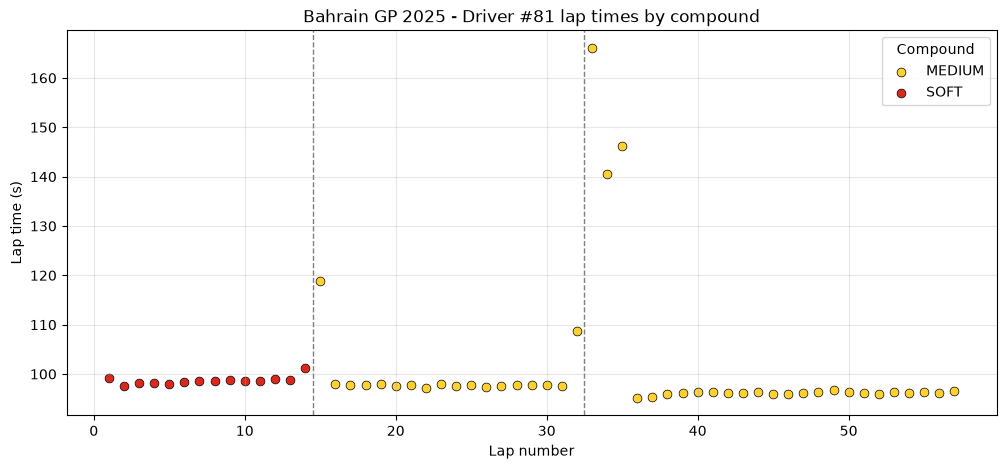

Laps without lap_duration (not plotted): 0


In [10]:
DRIVER = 81  # Oscar Piastri, race winner

# F1-style compound colors. HARD is white on TV graphics; we use light grey
# plus a black edge on every point so it stays visible on a white background.
COMPOUND_COLORS = {"SOFT": "#DA291C", "MEDIUM": "#FFD12E", "HARD": "#D9D9D9"}

driver_laps = laps_stints[laps_stints["driver_number"] == DRIVER]

# Object-oriented API: `fig` is the whole figure, `ax` is the plot area we draw on
fig, ax = plt.subplots(figsize=(12, 5))

# One scatter call per compound -> each compound gets its own color and legend entry
for compound, group in driver_laps.groupby("compound"):
    ax.scatter(
        group["lap_number"],
        group["lap_duration"],
        color=COMPOUND_COLORS.get(compound, "black"),  # Fallback for unexpected compounds
        edgecolors="black",
        linewidths=0.5,
        s=40,                                          # Marker size
        label=compound,
    )

# Dashed vertical line at each pit stop: the start of every stint except the first.
# Placed at lap - 0.5 so the line sits BETWEEN the in-lap and the out-lap.
pit_laps = stints.loc[
    (stints["driver_number"] == DRIVER) & (stints["stint_number"] > 1), "lap_start"
]
for lap in pit_laps:
    ax.axvline(lap - 0.5, color="grey", linestyle="--", linewidth=1)

ax.set_xlabel("Lap number")
ax.set_ylabel("Lap time (s)")
ax.set_title(f"Bahrain GP 2025 - Driver #{DRIVER} lap times by compound")
ax.legend(title="Compound")
ax.grid(alpha=0.3)
plt.show()

# Laps with no time are silently skipped by scatter, so we report them explicitly
n_no_time = driver_laps["lap_duration"].isna().sum()
print(f"Laps without lap_duration (not plotted): {n_no_time}")

### 5.1 Verify the Safety Car
Race control messages confirm hypothesis 4 with data instead of memory.

In [11]:
# Race control messages filtered to Safety Car events (cached like everything else)
sc_messages = pd.DataFrame(
    fetch_openf1("race_control", {"session_key": SESSION_KEY, "category": "SafetyCar"})
)
sc_messages[["lap_number", "message"]]

[cache] race_control__category=SafetyCar_session_key=10014.json


,lap_number,message
0,32,SAFETY CAR DEPLOYED
1,35,SAFETY CAR IN THIS LAP


### Findings: hypotheses vs data

| # | Hypothesis | Result | Evidence |
|---|---|---|---|
| 1 | Pit laps are slower | Confirmed | In-lap 14 ≈ 101 s (+2–3 s). Out-lap 15 ≈ 119 s, about **+21 s** vs a normal lap: a first real measurement of pit loss, in line with the expected 18-25 s. |
| 2 | Degradation vs fuel effect | Confirmed, with a caveat | SOFT stint rises ≈ 97.5 → 99 s (degradation wins). MEDIUM stint 2 is almost **flat**: the fuel effect may be hiding the degradation. MEDIUM stint 3 rises ≈ 95 → 96.5 s. |
| 3 | Lap 1 is very different | Not for this driver | Lap 1 ≈ 99 s, only ~1.5 s slower than lap 2. Piastri started from pole: clean air, no traffic in the first corners. Expected to differ for drivers starting further back. |
| 4 | Something unusual near lap 32 | Confirmed | Safety Car deployed on lap 32 (in on lap 35) after the Sainz–Tsunoda collision. Piastri pitted under it (in-lap 32, out-lap 33 ≈ 166 s). Laps 34-35 ≈ 140-146 s. |

**Other observations**
- Stint 3 is about 2 s faster than stint 2 with the same compound (new MEDIUM), explained by lower fuel load and track evolution (more rubber on the surface).
- The Safety Car stop cost about the same lap-time delta as a normal stop (~+23 s vs SC laps).
  Its real advantage is the field bunching up behind the Safety Car, which lap times alone cannot show: it requires gaps between drivers.
- Safety Car and pit laps squash the y-axis, hiding the 1–2 s degradation signal.